In [22]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [44]:
# Load customer churn dataset

df = pd.read_csv(r"C:\Users\Nenshi\Downloads\WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Display first 5 rows
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [24]:
# Check dataset shape
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset Information:")
df.info()

Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    


In [25]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())


Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate Rows: 0


In [26]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("TotalCharges Data Type:", df["TotalCharges"].dtype)
print("Missing Values after Conversion:", df["TotalCharges"].isnull().sum())

display(df[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].head())

TotalCharges Data Type: float64
Missing Values after Conversion: 11


,tenure,MonthlyCharges,TotalCharges,Churn
0,1,29.85,29.85,No
1,34,56.95,1889.50,No
2,2,53.85,108.15,Yes
3,45,42.30,1840.75,No
4,2,70.70,151.65,Yes


In [27]:
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

print("Missing Values after Cleaning:", df.isnull().sum().sum())
print("Dataset Shape:", df.shape)

Missing Values after Cleaning: 0
Dataset Shape: (7043, 21)


Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


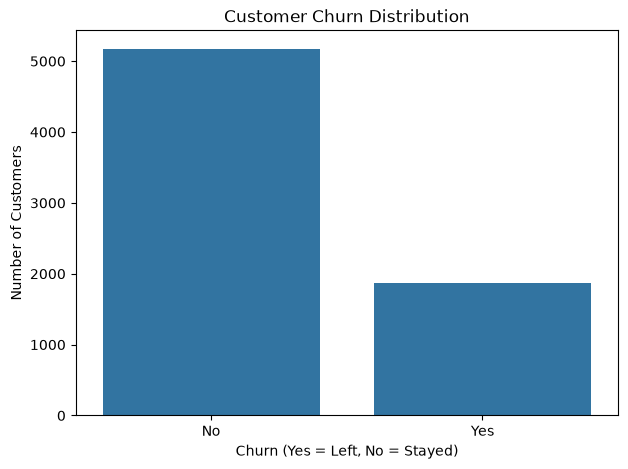

In [28]:
# Count customers who churned and stayed
print("Churn Distribution:")
print(df["Churn"].value_counts())

# Plot the graph
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (Yes = Left, No = Stayed)")
plt.ylabel("Number of Customers")
plt.show()

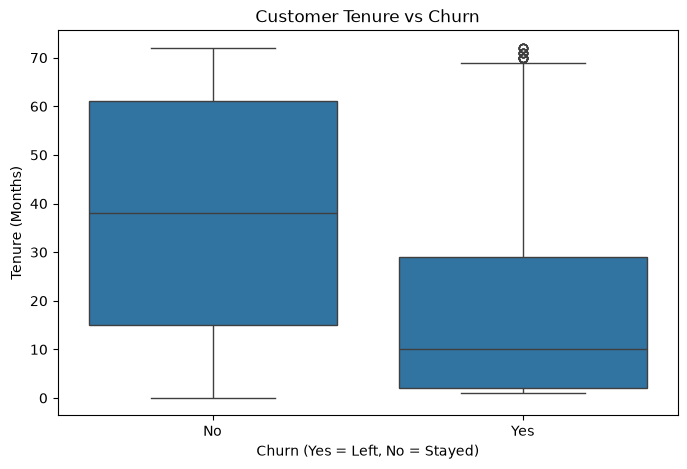

In [29]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn (Yes = Left, No = Stayed)")
plt.ylabel("Tenure (Months)")
plt.show()

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid", context="notebook")

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 16
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["figure.dpi"] = 110

print("Attractive Graph Theme Applied Successfully!")

Attractive Graph Theme Applied Successfully!


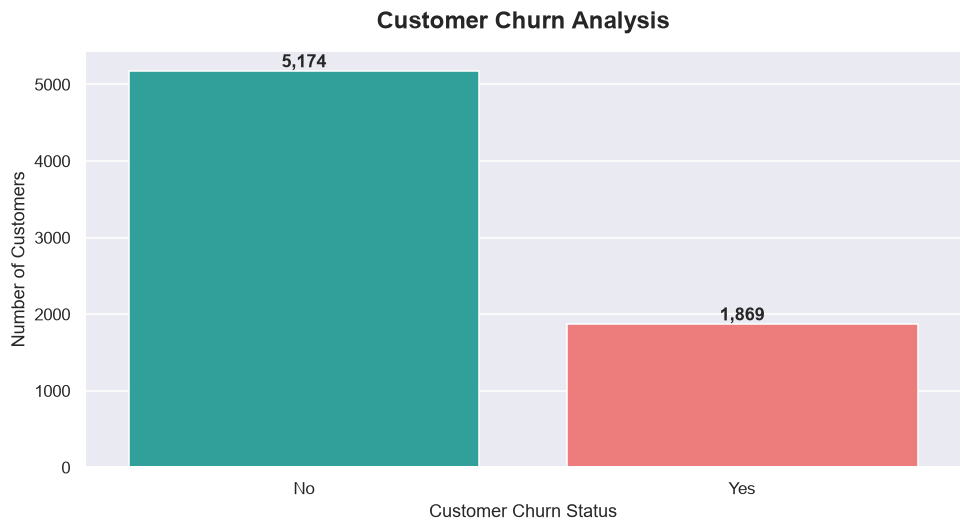

In [32]:
churn_counts = df["Churn"].value_counts().reindex(["No", "Yes"])

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=churn_counts.index,
    y=churn_counts.values,
    hue=churn_counts.index,
    palette={"No": "#20B2AA", "Yes": "#FF6B6B"},
    legend=False
)

for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height()):,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

plt.title("Customer Churn Analysis", fontweight="bold", pad=15)
plt.xlabel("Customer Churn Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

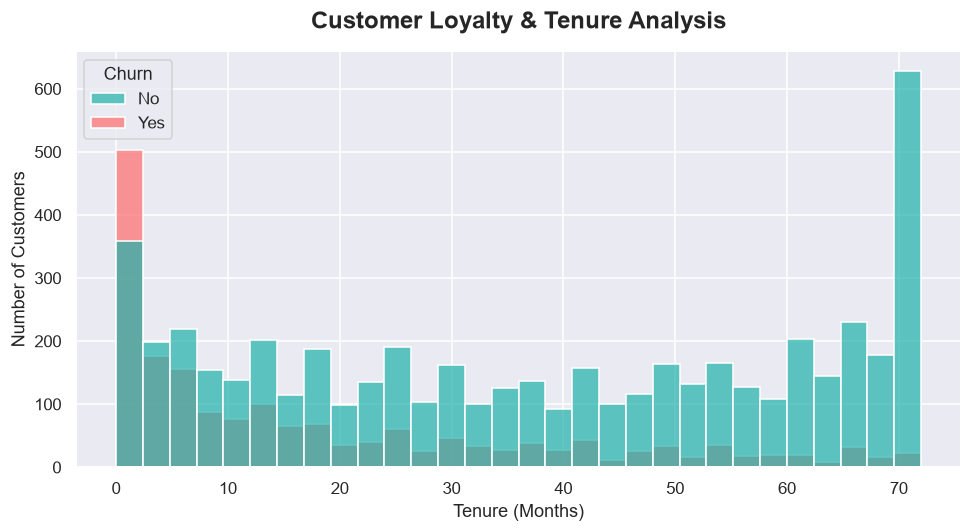

In [38]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="layer",
    palette={"No": "#20B2AA", "Yes": "#FF6B6B"},
    alpha=0.7
)

plt.title("Customer Loyalty & Tenure Analysis", fontweight="bold", pad=15)
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

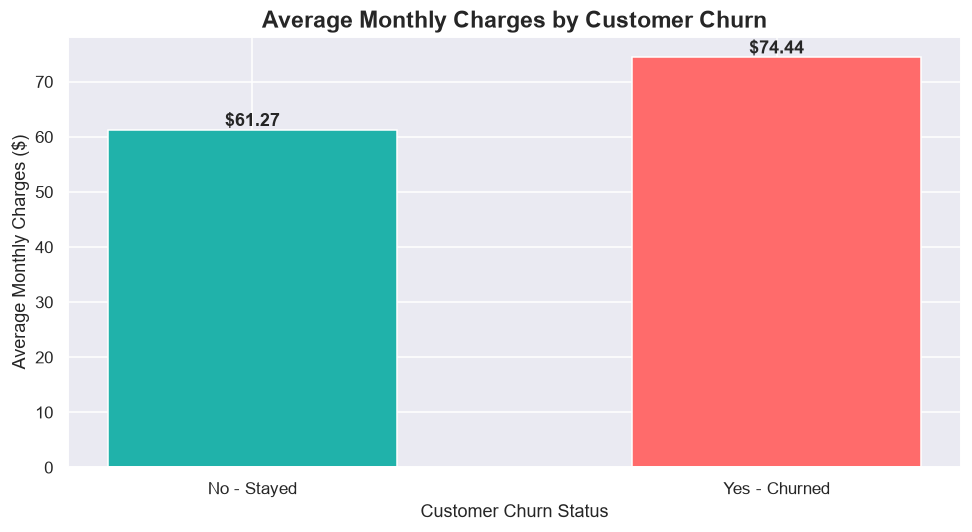

In [40]:
# Calculate average monthly charges for each churn group
avg_charges = df.groupby("Churn")["MonthlyCharges"].mean()
avg_charges = avg_charges.reindex(["No", "Yes"])

# Create an attractive bar graph
plt.figure(figsize=(9, 5))

bars = plt.bar(
    avg_charges.index,
    avg_charges.values,
    color=["#20B2AA", "#FF6B6B"],
    width=0.55
)

# Display values above the bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"${height:.2f}",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

plt.title("Average Monthly Charges by Customer Churn",
          fontsize=15, fontweight="bold")
plt.xlabel("Customer Churn Status")
plt.ylabel("Average Monthly Charges ($)")
plt.xticks([0, 1], ["No - Stayed", "Yes - Churned"])
plt.tight_layout()
plt.show()

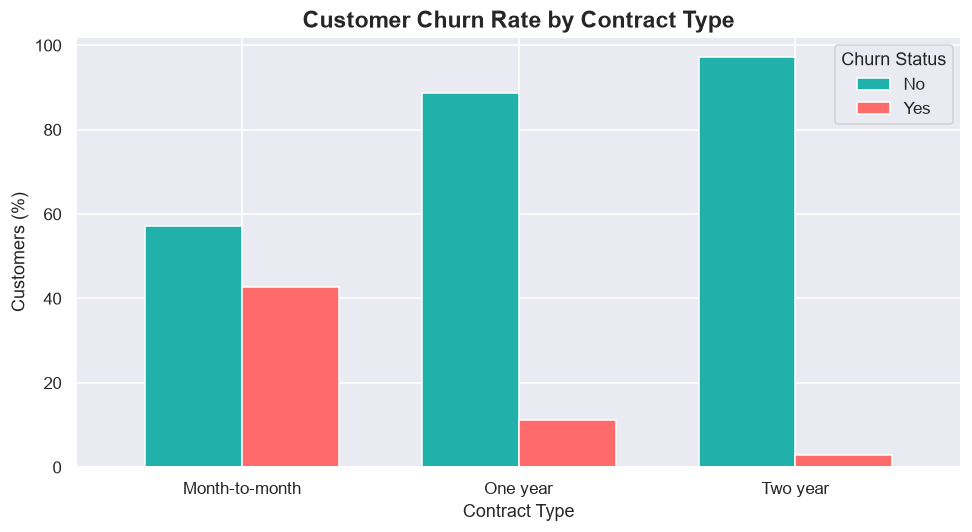

In [41]:
# Calculate churn percentage for each contract type
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn = contract_churn.reindex(
    columns=["No", "Yes"]
)

# Create an attractive bar graph
ax = contract_churn.plot(
    kind="bar",
    figsize=(9, 5),
    color=["#20B2AA", "#FF6B6B"],
    width=0.7
)

plt.title("Customer Churn Rate by Contract Type",
          fontsize=15, fontweight="bold")
plt.xlabel("Contract Type")
plt.ylabel("Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn Status")
plt.tight_layout()
plt.show()

 # Data Preprocessing

In [45]:
df = pd.read_csv(r"C:\Users\Nenshi\Downloads\WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [46]:
# Convert TotalCharges into numeric values
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Fill missing values
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

# Remove customer ID
df = df.drop("customerID", axis=1)

# Separate input and target
X = df.drop("Churn", axis=1)
y = df["Churn"].map({"Yes": 1, "No": 0})

print("Dataset Shape:", df.shape)
print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

Dataset Shape: (7043, 20)
Input Shape: (7043, 19)
Target Shape: (7043,)


In [47]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [48]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Preprocessing for numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Data Preprocessing Setup Completed Successfully!")

Data Preprocessing Setup Completed Successfully!


In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (5634, 19)
Testing Features: (1409, 19)
Training Target: (5634,)
Testing Target: (1409,)


In [ ]:
# Train Logistic Regression Model

In [50]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create the complete machine learning model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [51]:
# Predict customer churn
y_pred = model.predict(X_test)

print("First 10 Actual Values:", y_test.iloc[:10].tolist())
print("First 10 Predicted Values:", y_pred[:10].tolist())

First 10 Actual Values: [0, 0, 0, 0, 0, 0, 0, 0, 0, 1]
First 10 Predicted Values: [0, 1, 0, 0, 0, 1, 0, 0, 0, 0]


In [52]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

Accuracy : 0.8055 (80.55%)
Precision: 0.6572
Recall   : 0.5588
F1-Score : 0.6040

Classification Report:

              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



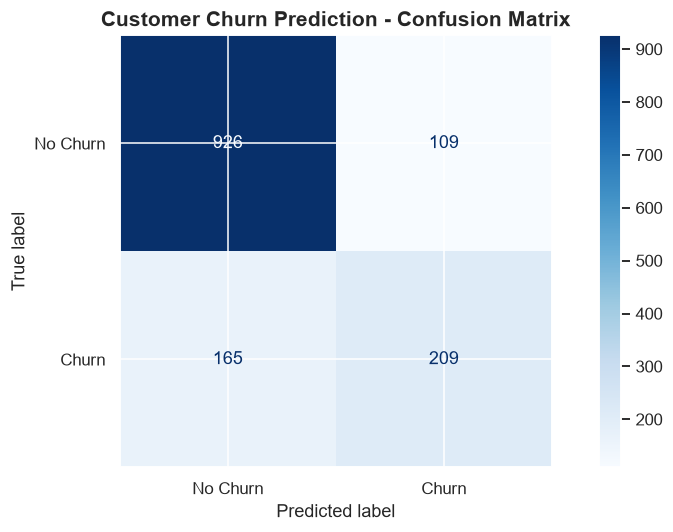

In [53]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Customer Churn Prediction - Confusion Matrix",
          fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [54]:

# Select one customer as a sample
new_customer = X.iloc[[0]].copy()

# Change selected customer details for demonstration
new_customer.loc[:, "tenure"] = 2
new_customer.loc[:, "MonthlyCharges"] = 85.5
new_customer.loc[:, "Contract"] = "Month-to-month"

# Predict customer churn
prediction = model.predict(new_customer)[0]

# Get probability of churn
probability = model.predict_proba(new_customer)[0][1]

print("Customer Churn Prediction")
print("-------------------------")
print("Predicted Churn:", "Yes" if prediction == 1 else "No")
print(f"Churn Probability: {probability * 100:.2f}%")


Customer Churn Prediction
-------------------------
Predicted Churn: No
Churn Probability: 33.31%


In [55]:

print("=" * 55)
print(" CUSTOMER CHURN PREDICTION - PROJECT CONCLUSION")
print("=" * 55)

print("\n1. Project Objective:")
print("   To predict whether a customer will leave the service.")

print("\n2. Dataset Information:")
print("   Dataset: Telco Customer Churn")
print("   Total Records: 7043")
print("   Target Variable: Churn")

print("\n3. Data Preprocessing:")
print("   - Handled missing TotalCharges values")
print("   - Encoded categorical features")
print("   - Scaled numerical features")
print("   - Split data into training and testing sets")

print("\n4. Machine Learning Algorithm:")
print("   Logistic Regression")

print("\n5. Model Performance:")
print(f"   Accuracy  : {accuracy * 100:.2f}%")
print(f"   Precision : {precision:.4f}")
print(f"   Recall    : {recall:.4f}")
print(f"   F1-Score  : {f1:.4f}")

print("\n6. Conclusion:")
print("   The model achieved 80.55% accuracy on the test dataset.")
print("   It can help identify customers who may leave the service.")
print("   Further improvements may help detect more churn customers.")

print("\n" + "=" * 55)

 CUSTOMER CHURN PREDICTION - PROJECT CONCLUSION

1. Project Objective:
   To predict whether a customer will leave the service.

2. Dataset Information:
   Dataset: Telco Customer Churn
   Total Records: 7043
   Target Variable: Churn

3. Data Preprocessing:
   - Handled missing TotalCharges values
   - Encoded categorical features
   - Scaled numerical features
   - Split data into training and testing sets

4. Machine Learning Algorithm:
   Logistic Regression

5. Model Performance:
   Accuracy  : 80.55%
   Precision : 0.6572
   Recall    : 0.5588
   F1-Score  : 0.6040

6. Conclusion:
   The model achieved 80.55% accuracy on the test dataset.
   It can help identify customers who may leave the service.
   Further improvements may help detect more churn customers.

